# 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

print("Libraries imported successfully.")

Libraries imported successfully.


# 2. Load the data

In [2]:
data = pd.read_csv("OnlineRetail.csv", encoding='latin1')
data.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


# 3.Check the datase

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [4]:
df=data.copy()

# 4.Missing values and duplicates

In [5]:
print("missing values:")
df.isna().sum()

missing values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

### Revenue = Active Customer Count * Order Count * Average Revenue per Order

In [6]:
# converting Invoice Date Field from string to datetime.
df['InvoiceDate'] = pd.to_datetime(data["InvoiceDate"])

# creating YearMonth field 
df['InvoiceYearMonth'] = df['InvoiceDate'].map(
    lambda date: 100*date.year + date.month)

# درآمد هر ردیف = قیمت واحد × تعداد 
df['Revenue'] = df['UnitPrice'] * df['Quantity']
df_revenue = df.groupby(['InvoiceYearMonth'])['Revenue'].sum().reset_index()
df_revenue

,InvoiceYearMonth,Revenue
0,201012,748957.020
1,201101,560000.260
2,201102,498062.650
3,201103,683267.080
4,201104,493207.121
5,201105,723333.510
6,201106,691123.120
7,201107,681300.111
8,201108,682680.510
9,201109,1019687.622


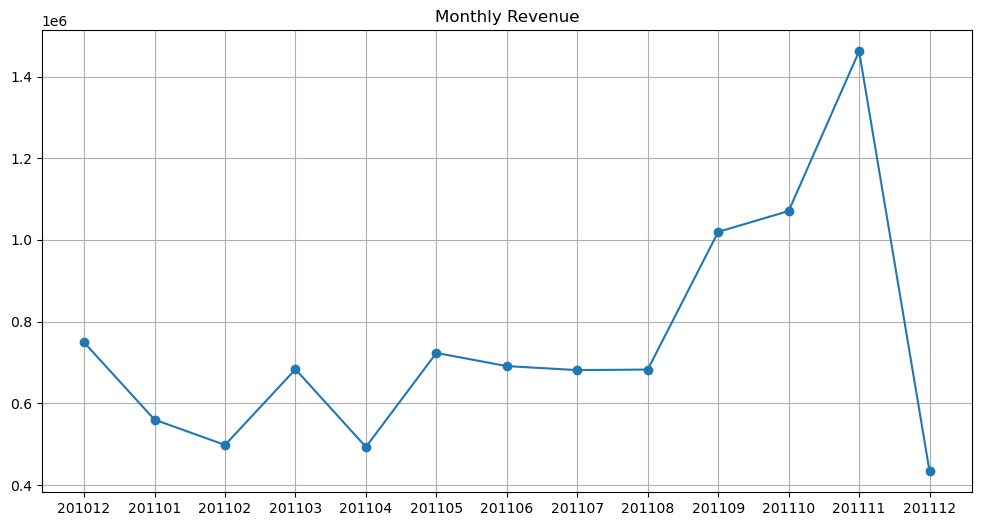

In [7]:
plt.figure(figsize=(12, 6))
plt.title('Monthly Revenue')
plt.plot(df_revenue['InvoiceYearMonth'].astype(str), df_revenue['Revenue'], marker='o')
plt.grid()
plt.show()

In [8]:
df_revenue['MonthlyGrowth'] = df_revenue['Revenue'].pct_change()
df_revenue

,InvoiceYearMonth,Revenue,MonthlyGrowth
0,201012,748957.020,NaN
1,201101,560000.260,-0.252293
2,201102,498062.650,-0.110603
3,201103,683267.080,0.371850
4,201104,493207.121,-0.278163
5,201105,723333.510,0.466592
6,201106,691123.120,-0.044530
7,201107,681300.111,-0.014213
8,201108,682680.510,0.002026
9,201109,1019687.622,0.493653


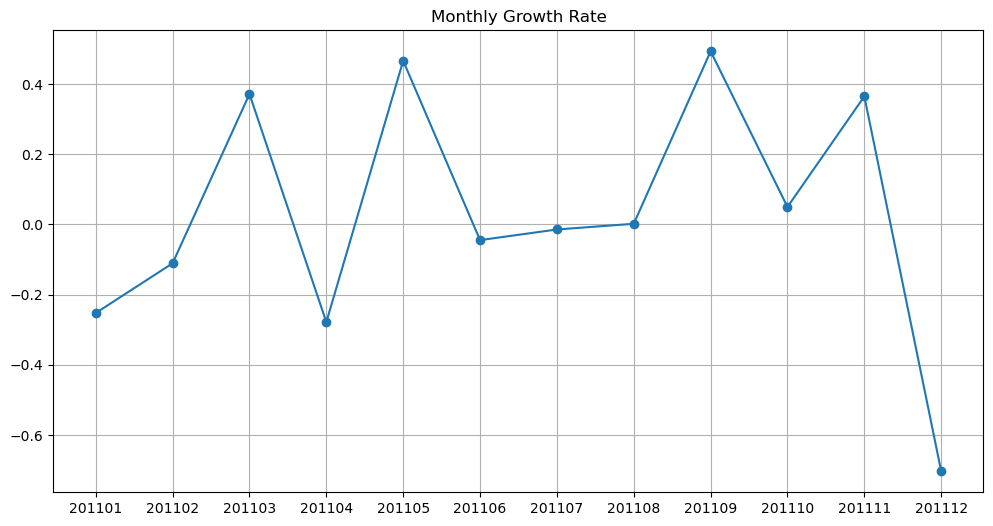

In [9]:
plt.figure(figsize=(12, 6))
plt.title('Monthly Growth Rate')
plt.plot(df_revenue['InvoiceYearMonth'].astype(
    str), df_revenue['MonthlyGrowth'], marker='o')
plt.grid()
plt.show()

Everything looks good, we saw 36.5% growth previous month (December is excluded in the code since it hasn’t been completed yet).

But we need to identify what exactly happened on April.


# Monthly Active Customers
 We can get the monthly active customers by counting unique CustomerIDs. 

In [10]:
df_uk = df.query("Country=='United Kingdom'").reset_index(drop=True)

df_monthly_active = df_uk.groupby('InvoiceYearMonth')['CustomerID'].nunique().reset_index()

df_monthly_active

,InvoiceYearMonth,CustomerID
0,201012,871
1,201101,684
2,201102,714
3,201103,923
4,201104,817
5,201105,985
6,201106,943
7,201107,899
8,201108,867
9,201109,1177


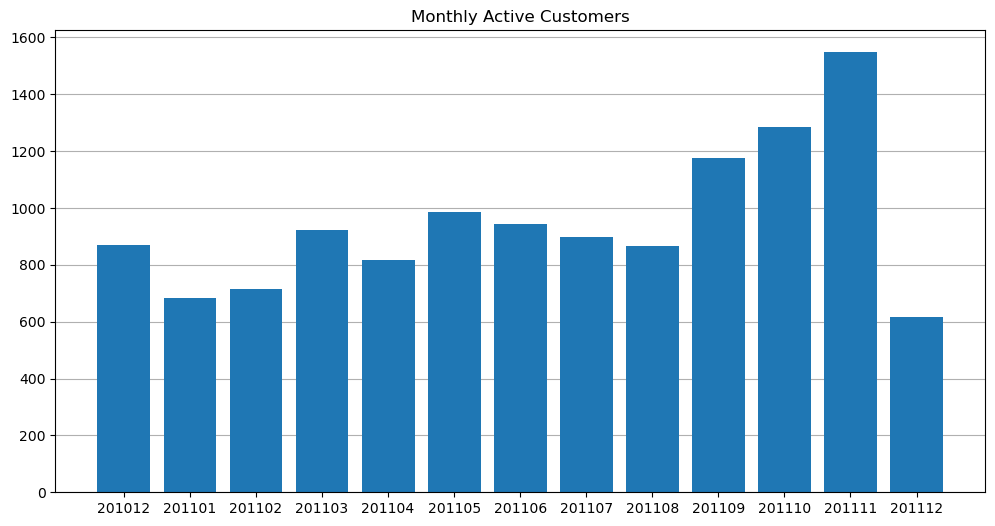

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('Monthly Active Customers')
ax.bar(df_monthly_active['InvoiceYearMonth'].astype(str), df_monthly_active['CustomerID'])
ax.grid(axis='y')
ax.set_axisbelow(True)
plt.show()

In April, Monthly Active Customer number decrease (-11.5%) 

# Monthly Order Count

In [12]:
df_monthly_sales = df_uk.groupby('InvoiceYearMonth')['Quantity'].sum().reset_index()

df_monthly_sales

,InvoiceYearMonth,Quantity
0,201012,298101
1,201101,237381
2,201102,225641
3,201103,279843
4,201104,257666
5,201105,306452
6,201106,258522
7,201107,324129
8,201108,319804
9,201109,458490


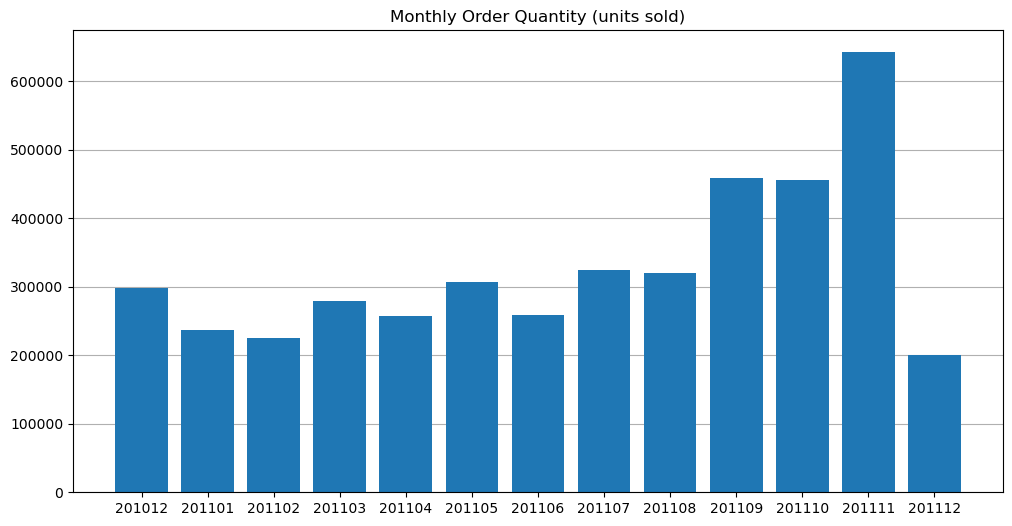

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('Monthly Order Quantity (units sold)')
ax.bar(df_monthly_sales['InvoiceYearMonth'].astype(str), df_monthly_sales['Quantity'])
ax.grid(axis='y')
ax.set_axisbelow(True)
plt.show()

As we expected, Order Count is also declined in April (279k to 257k, -8%).

We know that Active Customer Count directly affected Order Count decrease.

# Average Revenue per Order

In [14]:
df_monthly_order_avg = df_uk.groupby('InvoiceYearMonth')[
    'Revenue'].mean().reset_index() 

df_monthly_order_avg

,InvoiceYearMonth,Revenue
0,201012,16.865860
1,201101,13.614680
2,201102,16.093027
3,201103,16.716166
4,201104,15.773380
5,201105,17.713823
6,201106,16.714748
7,201107,15.723497
8,201108,17.315899
9,201109,18.931723


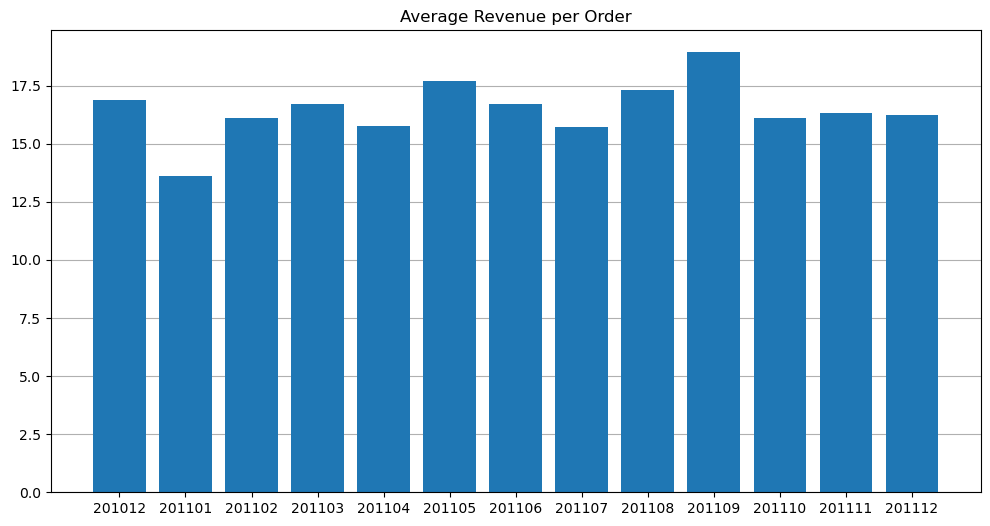

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_title('Average Revenue per Order')
ax.bar(df_monthly_order_avg['InvoiceYearMonth'].astype(str), df_monthly_order_avg['Revenue'])
ax.grid(axis='y')
ax.set_axisbelow(True)
plt.show()

Even the monthly order average dropped for April (16.7 to 15.8). We observed slow-down in every metric affecting our North Star

In [16]:
# اولین ماه خرید هر مشتری
first_purchase_month = (
    df_uk.groupby("CustomerID")["InvoiceYearMonth"]
    .min()
    .rename("FirstPurchaseMonth")
)

# اضافه کردن اولین ماه خرید به دیتافریم اصلی
df_uk = df_uk.merge(
    first_purchase_month,
    on="CustomerID",
    how="left"
)

# تعیین نوع مشتری
df_uk["UserType"] = np.where(
    df_uk["InvoiceYearMonth"] == df_uk["FirstPurchaseMonth"],
    "New",
    "Existing"
)

df_uk[[
    "CustomerID",
    "InvoiceYearMonth",
    "FirstPurchaseMonth",
    "UserType"
]].head()


,CustomerID,InvoiceYearMonth,FirstPurchaseMonth,UserType
0,17850.0,201012,201012.0,New
1,17850.0,201012,201012.0,New
2,17850.0,201012,201012.0,New
3,17850.0,201012,201012.0,New
4,17850.0,201012,201012.0,New


In [17]:
# تعداد مشتریان جدید در هر ماه
df_new_customers = (
    df_uk[df_uk["UserType"] == "New"]
    .groupby("InvoiceYearMonth")["CustomerID"]
    .nunique()
)

# تعداد مشتریان قدیمی در هر ماه
df_existing_customers = (
    df_uk[df_uk["UserType"] == "Existing"]
    .groupby("InvoiceYearMonth")["CustomerID"]
    .nunique()
)

# ترکیب دو سری در یک دیتافریم
df_user_ratio = pd.concat(
    [
        df_new_customers.rename("NewCustomers"),
        df_existing_customers.rename("ExistingCustomers")
    ],
    axis=1
).fillna(0)

# جلوگیری از تقسیم بر صفر
df_user_ratio["NewToExistingRatio"] = np.where(
    df_user_ratio["ExistingCustomers"] == 0,
    0,
    df_user_ratio["NewCustomers"] /
    df_user_ratio["ExistingCustomers"]
)

# تبدیل شاخص ماه به ستون
df_user_ratio = df_user_ratio.reset_index()

df_user_ratio


,InvoiceYearMonth,NewCustomers,ExistingCustomers,NewToExistingRatio
0,201012,871,0,0.000000
1,201101,362,322,1.124224
2,201102,339,375,0.904000
3,201103,408,515,0.792233
4,201104,276,541,0.510166
5,201105,252,733,0.343793
6,201106,207,736,0.281250
7,201107,172,727,0.236589
8,201108,140,727,0.192572
9,201109,275,902,0.304878


In [18]:
print(df_uk[["InvoiceYearMonth", "UserType"]].isna().sum())
print(df_uk["UserType"].value_counts())
print(df_uk["InvoiceYearMonth"].min())
print(df_uk["InvoiceYearMonth"].max())


InvoiceYearMonth    0
UserType            0
dtype: int64
UserType
Existing    389714
New         105764
Name: count, dtype: int64
201012
201112


In [19]:
pd.crosstab(
    df_uk["InvoiceYearMonth"],
    df_uk["UserType"]
)


UserType,Existing,New
InvoiceYearMonth,,
201012,15589,24536
201101,22707,9193
201102,17428,7940
201103,23516,9967
201104,21262,6776
201105,28372,5300
201106,28498,4675
201107,31759,4205
201108,27351,3784


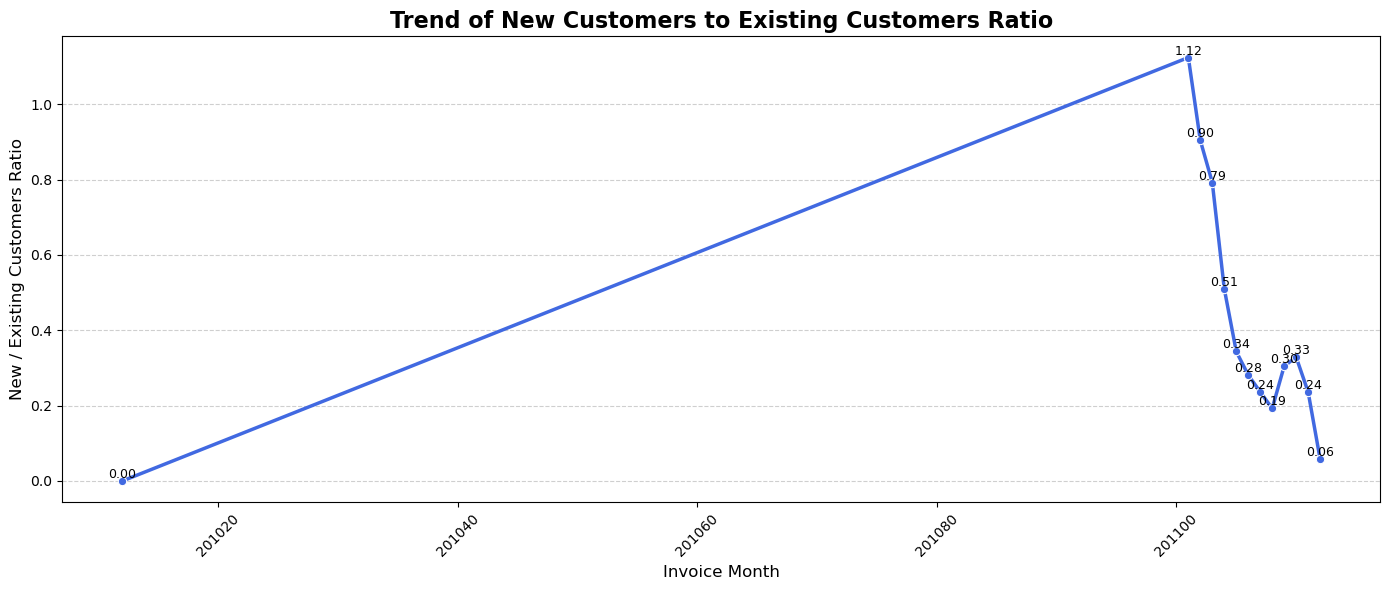

In [20]:
plt.figure(figsize=(14, 6))

ax = sns.lineplot(
    data=df_user_ratio,
    x="InvoiceYearMonth",
    y="NewToExistingRatio",
    marker="o",
    linewidth=2.5,
    color="royalblue"
)

for index, row in df_user_ratio.iterrows():
    ax.text(
        row["InvoiceYearMonth"],
        row["NewToExistingRatio"],
        f'{row["NewToExistingRatio"]:.2f}',
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title(
    "Trend of New Customers to Existing Customers Ratio",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Invoice Month", fontsize=12)
plt.ylabel("New / Existing Customers Ratio", fontsize=12)

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


In [21]:
#عدم نمایش ماه های اول در نمودار
df_user_ratio["NewToExistingRatio"] = (
    df_user_ratio["NewCustomers"]
    .div(df_user_ratio["ExistingCustomers"])
    .replace([np.inf, -np.inf], np.nan)
)


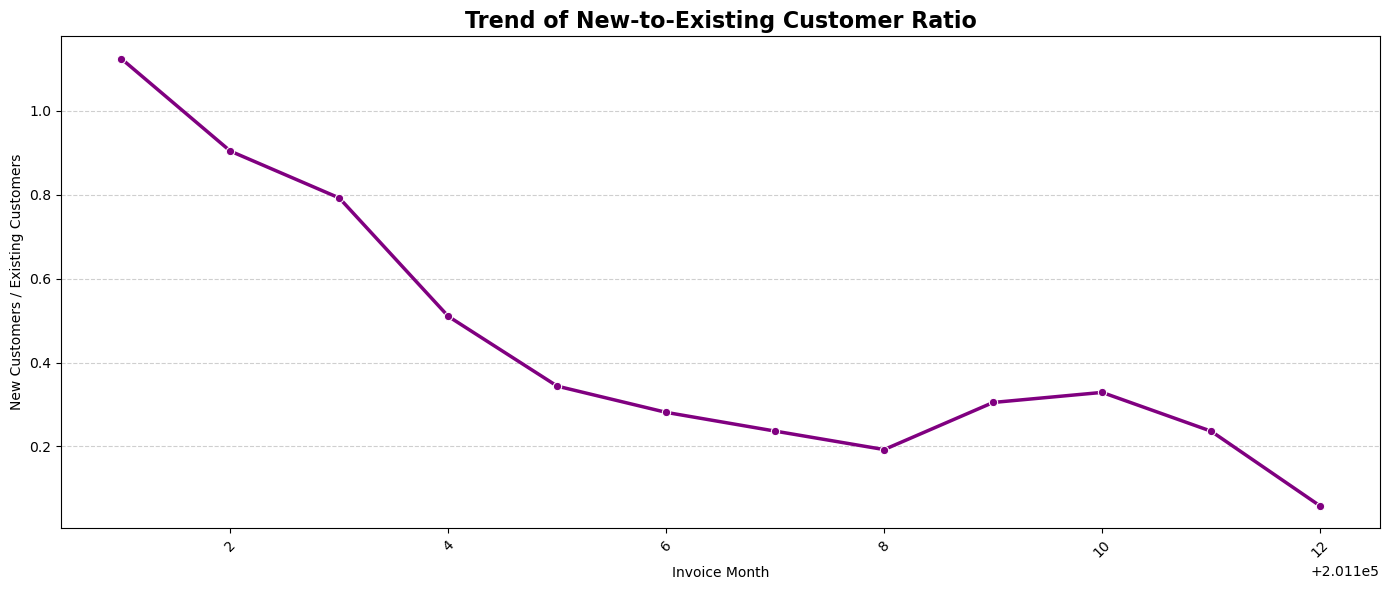

In [22]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df_user_ratio,
    x="InvoiceYearMonth",
    y="NewToExistingRatio",
    marker="o",
    linewidth=2.5,
    color="purple"
)

plt.title(
    "Trend of New-to-Existing Customer Ratio",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Invoice Month")
plt.ylabel("New Customers / Existing Customers")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


# نتیجه گیری
عملکرد فروش در نیمه دوم سال، به‌ویژه در سپتامبر تا نوامبر، بهتر شده است؛ اما برای حفظ رشد پایدار، کسب‌وکار باید روی جذب مشتریان جدید، حفظ مشتریان فعلی و افزایش ارزش هر خرید تمرکز کند. همچنین پیش از تحلیل نهایی بهتر است مقادیر گمشده، سفارش‌های لغوشده و تراکنش‌های دارای تعداد یا قیمت منفی نیز بررسی و پاک‌سازی شوند.در این دیتاست صرفا تحلیل های اولیه جهت درک دلیل افت فروش و روند نزولی پیشرفت صورت گرفته و هیچ پاکسازی داده ای انجام نشده